# Mini project : Student academic performance & Student_dropout_risk_2026

**Subject:** Data Analysis & Visualization

**Tools:** python,pandas,Numpy,Matplotlib,Seaborn

**Dataset:** student_dropout_risk_2026.csv


# Aim

to clean a student academic dataset using pandas, analysize indicators using numpy,
visualize patterns using matplotlib and seaborn

# 1. Import Libraries

In [4]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# 2. Load the dataset

In [5]:
import pandas as pd 
df = pd.read_csv(r"C:\Users\Sayali\Downloads\archive (1)\student_dropout_risk_2026.csv")
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 100000
Number of columns: 34


,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,course_type,study_mode,semester,international_student,admission_grade,previous_qualification_grade,units_enrolled,units_passed,units_failed,gpa_semester_1,gpa_semester_2,attendance_rate,assignments_submitted_rate,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,24,STEM,Online,7,0,164.6,165.1,11,11,0,3.44,2.55,77.3,75.0,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,0,Arts & Humanities,Full-time,6,1,175.2,164.1,14,11,3,2.56,2.53,52.1,80.1,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,16,Arts & Humanities,Full-time,3,0,126.0,179.3,17,14,3,3.43,2.73,100.0,67.8,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,0,Business,Full-time,1,0,75.5,161.9,13,11,2,2.51,2.10,83.9,100.0,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,0,Health Sciences,Part-time,2,0,89.0,101.8,8,7,1,3.93,2.88,61.6,100.0,4,7.4,1,0,7,0,10,24,5.8,0


# column names and data types

In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


Column names:
['person_id', 'age', 'gender', 'nationality', 'first_generation', 'disability_status', 'family_income_level', 'scholarship_holder', 'tuition_up_to_date', 'part_time_job', 'weekly_work_hours', 'course_type', 'study_mode', 'semester', 'international_student', 'admission_grade', 'previous_qualification_grade', 'units_enrolled', 'units_passed', 'units_failed', 'gpa_semester_1', 'gpa_semester_2', 'attendance_rate', 'assignments_submitted_rate', 'library_visits_per_month', 'lms_logins_per_week', 'extracurricular_activities', 'missed_deadlines', 'stress_level', 'mental_health_support', 'satisfaction_score', 'commute_time_mins', 'sleep_hours', 'dropout']

Data types:
person_id                         int64
age                               int64
gender                           object
nationality                      object
first_generation                  int64
disability_status                 int64
family_income_level              object
scholarship_holder                int6

# clean and prepare the data

In [7]:
# Make a copy so the original data stays unchanged
data = df.copy()

# Remove exact duplicate rows, if any
data = data.drop_duplicates()

# Check for missing values
print("Missing values:", data.isnull().sum().sum())

# Check the dropout labels
print(data["dropout"].value_counts())

# Check that the dropout column contains only 0 and 1
print("Dropout labels:", sorted(data["dropout"].unique()))

# Create readable labels for charts and tables
data["dropout_status"] = data["dropout"].map({
    0: "Not marked as dropout",
    1: "Marked as dropout"
})

display(data.head())

Missing values: 0
dropout
0    67996
1    32004
Name: count, dtype: int64
Dropout labels: [np.int64(0), np.int64(1)]


,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,course_type,study_mode,semester,international_student,admission_grade,previous_qualification_grade,units_enrolled,units_passed,units_failed,gpa_semester_1,gpa_semester_2,attendance_rate,assignments_submitted_rate,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout,dropout_status
0,1,23,Male,Brazil,0,0,Low,1,0,1,24,STEM,Online,7,0,164.6,165.1,11,11,0,3.44,2.55,77.3,75.0,4,16.3,0,3,8,0,6,37,5.7,0,Not marked as dropout
1,2,18,Other,USA,1,1,High,1,1,0,0,Arts & Humanities,Full-time,6,1,175.2,164.1,14,11,3,2.56,2.53,52.1,80.1,3,8.4,1,1,7,0,6,15,5.4,1,Marked as dropout
2,3,24,Other,USA,0,0,High,0,1,1,16,Arts & Humanities,Full-time,3,0,126.0,179.3,17,14,3,3.43,2.73,100.0,67.8,3,11.3,1,0,2,0,3,4,4.3,0,Not marked as dropout
3,4,25,Female,USA,0,1,Middle,1,1,0,0,Business,Full-time,1,0,75.5,161.9,13,11,2,2.51,2.10,83.9,100.0,2,13.2,1,1,5,0,7,10,6.7,0,Not marked as dropout
4,5,15,Female,Canada,0,0,Low,1,1,0,0,Health Sciences,Part-time,2,0,89.0,101.8,8,7,1,3.93,2.88,61.6,100.0,4,7.4,1,0,7,0,10,24,5.8,0,Not marked as dropout


# main statistics

In [8]:
total_students = len(data)

dropout_students = (data["dropout"] == 1).sum()

not_dropout_students = (data["dropout"] == 0).sum()

dropout_percentage = (
    dropout_students / total_students
) * 100

average_attendance = data["attendance_rate"].mean()

average_gpa = data["gpa_semester_2"].mean()

print("Total student records:", total_students)
print("Records marked as dropout:", dropout_students)
print("Records not marked as dropout:", not_dropout_students)

print("Dropout percentage:", round(dropout_percentage, 2), "%")
print("Average attendance:", round(average_attendance, 2), "%")
print("Average Semester 2 GPA:", round(average_gpa, 2))

Total student records: 100000
Records marked as dropout: 32004
Records not marked as dropout: 67996
Dropout percentage: 32.0 %
Average attendance: 75.1 %
Average Semester 2 GPA: 1.98


# dropout distribution

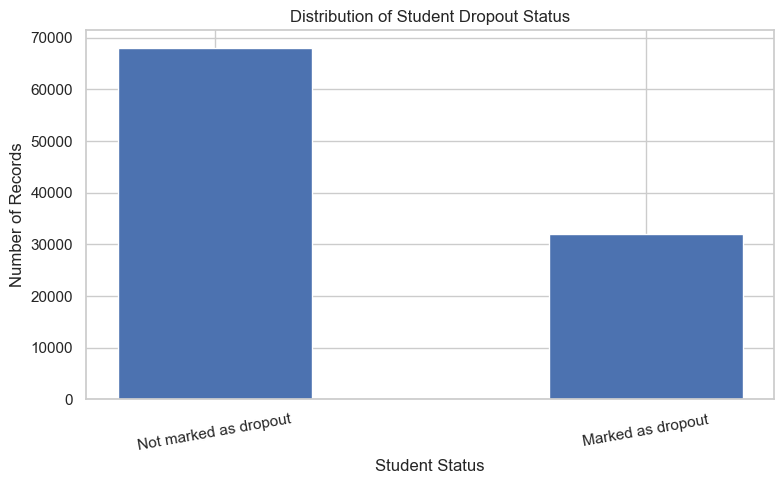

In [9]:
dropout_counts = data["dropout_status"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(
    dropout_counts.index,
    dropout_counts.values,
    width=0.45
)

plt.title("Distribution of Student Dropout Status")
plt.xlabel("Student Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# GPA change between semesters

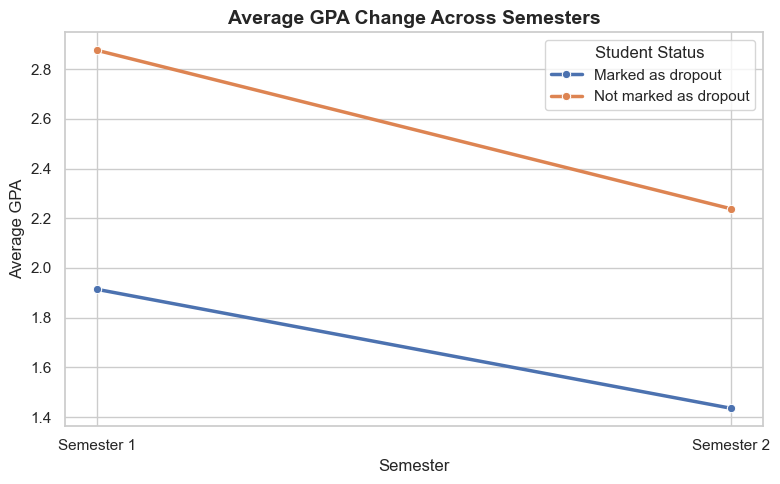

In [31]:
gpa_long = data.melt(
    id_vars=["dropout_status"],
    value_vars=["gpa_semester_1", "gpa_semester_2"],
    var_name="semester",
    value_name="gpa"
)
gpa_long["semester"] = gpa_long["semester"].map({
    "gpa_semester_1": "Semester 1",
    "gpa_semester_2": "Semester 2"
})

gpa_trend = (
    gpa_long.groupby(["dropout_status", "semester"], as_index=False)["gpa"]
    .mean()
)
gpa_trend["semester"] = pd.Categorical(
    gpa_trend["semester"],
    categories=["Semester 1", "Semester 2"],
    ordered=True
)
gpa_trend = gpa_trend.sort_values("semester")

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=gpa_trend,
    x="semester",
    y="gpa",
    hue="dropout_status",
    marker="o",
    linewidth=2.5
)
plt.title("Average GPA Change Across Semesters", fontsize=14, weight="bold")
plt.xlabel("Semester")
plt.ylabel("Average GPA")
plt.legend(title="Student Status")
plt.tight_layout()
plt.show()

# Attendence by student status

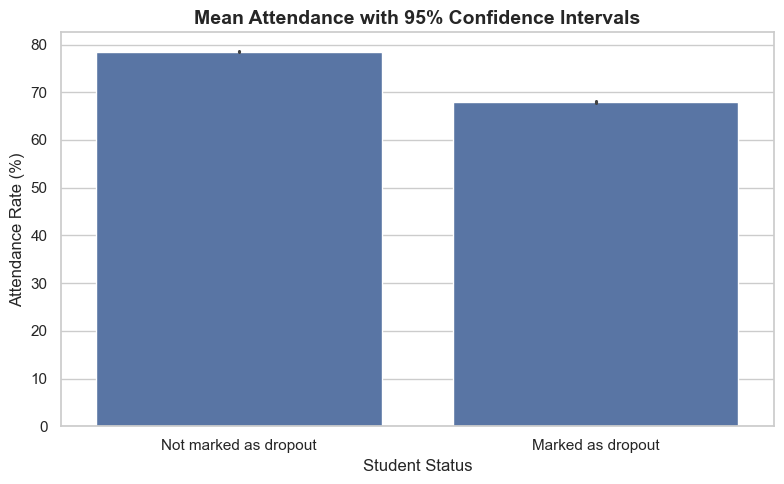

In [32]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=data,
    x="dropout_status",
    y="attendance_rate",
    errorbar=("ci", 95)
)
plt.title("Mean Attendance with 95% Confidence Intervals", fontsize=14, weight="bold")
plt.xlabel("Student Status")
plt.ylabel("Attendance Rate (%)")
plt.tight_layout()
plt.show()

# Attendence versus dropout status

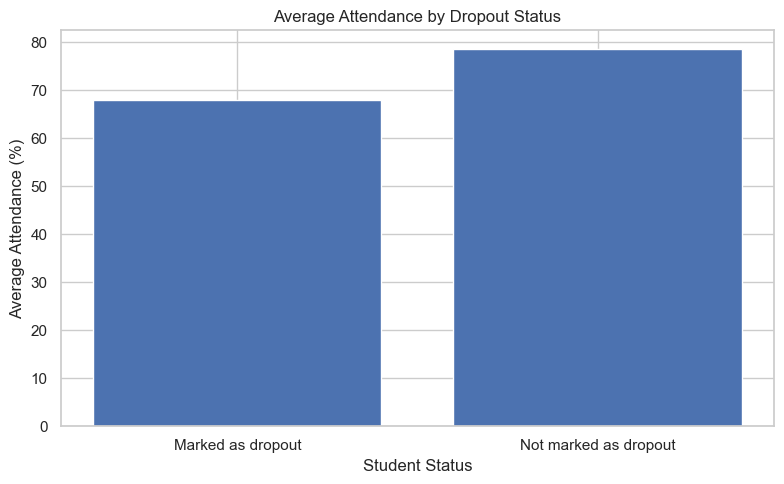

In [27]:
attendance = data.groupby(
    "dropout_status"
)["attendance_rate"].mean()

plt.figure(figsize=(8, 5))
plt.bar(attendance.index, attendance.values)

plt.title("Average Attendance by Dropout Status")
plt.xlabel("Student Status")
plt.ylabel("Average Attendance (%)")
plt.tight_layout()
plt.show()

# GPA comparison

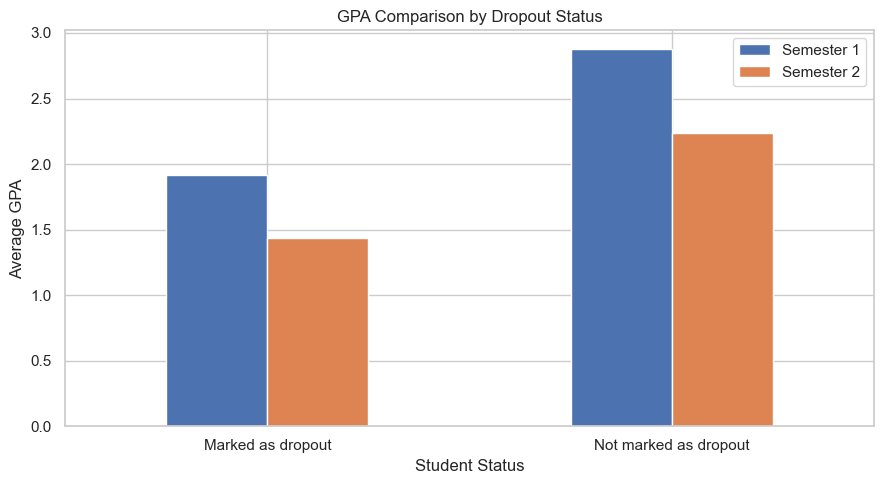

In [28]:
gpa = data.groupby("dropout_status")[
    ["gpa_semester_1", "gpa_semester_2"]
].mean()

gpa.plot(kind="bar", figsize=(9, 5))

plt.title("GPA Comparison by Dropout Status")
plt.xlabel("Student Status")
plt.ylabel("Average GPA")
plt.xticks(rotation=0)
plt.legend(["Semester 1", "Semester 2"])
plt.tight_layout()
plt.show()

# Attendence rate distribution

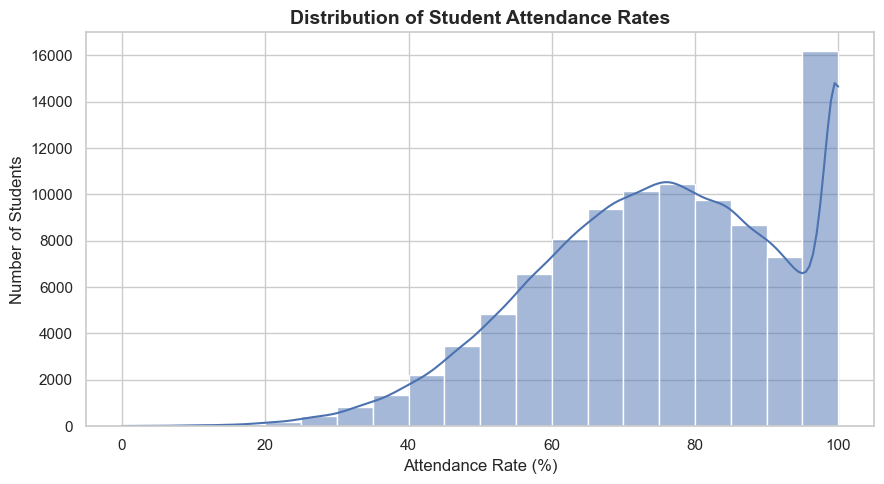

In [33]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=data,
    x="attendance_rate",
    bins=20,
    kde=True
)
plt.title("Distribution of Student Attendance Rates", fontsize=14, weight="bold")
plt.xlabel("Attendance Rate (%)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# dropout percentage by course

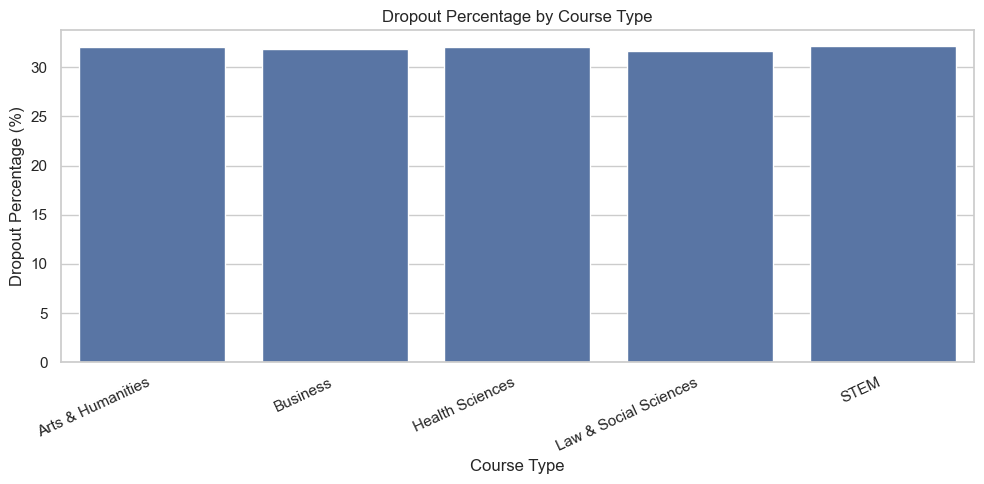

In [35]:
course_dropout = data.groupby(
    "course_type",
    as_index=False
)["dropout"].mean()

course_dropout["dropout"] *= 100

plt.figure(figsize=(10, 5))

sns.barplot(
    data=course_dropout,
    x="course_type",
    y="dropout"
)

plt.title("Dropout Percentage by Course Type")
plt.xlabel("Course Type")
plt.ylabel("Dropout Percentage (%)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

# Attendence versus semester 2 GPA

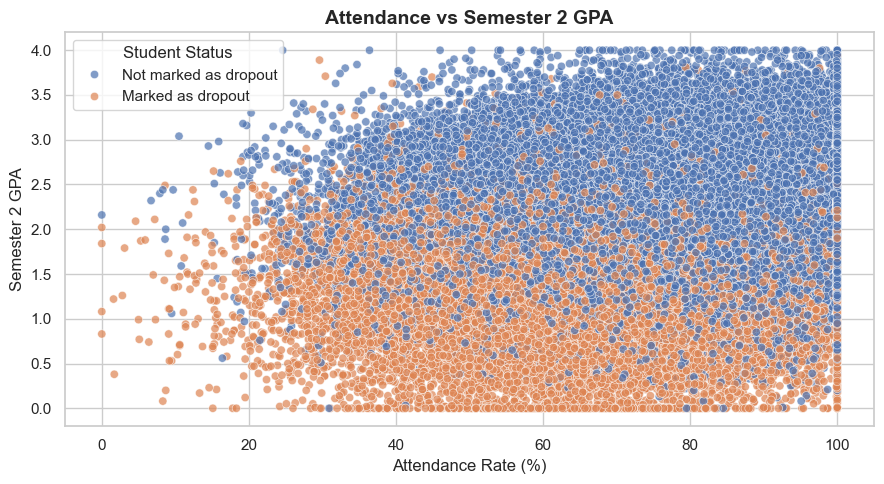

In [36]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=data,
    x="attendance_rate",
    y="gpa_semester_2",
    hue="dropout_status",
    alpha=0.7
)
plt.title("Attendance vs Semester 2 GPA", fontsize=14, weight="bold")
plt.xlabel("Attendance Rate (%)")
plt.ylabel("Semester 2 GPA")
plt.legend(title="Student Status")
plt.tight_layout()
plt.show()

# correlation heatmap

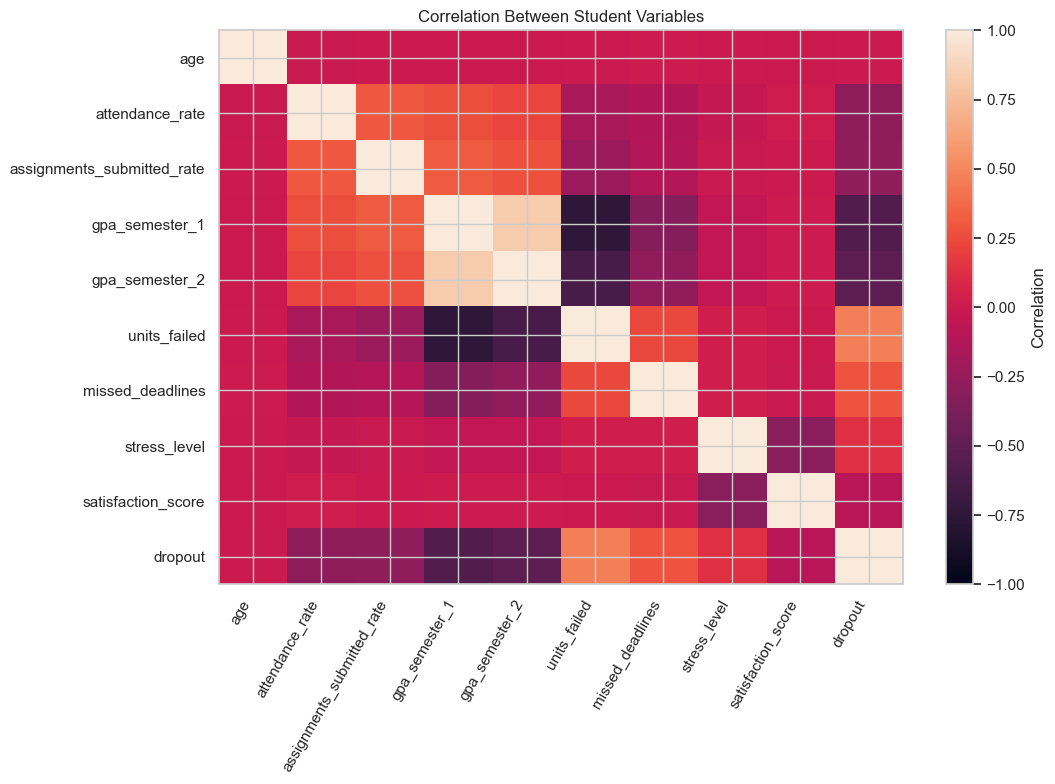

In [30]:
numeric_data = data[
    [
        "age",
        "attendance_rate",
        "assignments_submitted_rate",
        "gpa_semester_1",
        "gpa_semester_2",
        "units_failed",
        "missed_deadlines",
        "stress_level",
        "satisfaction_score",
        "dropout"
    ]
]

correlation = numeric_data.corr()

plt.figure(figsize=(11, 8))

plt.imshow(correlation, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=60,
    ha="right"
)

plt.yticks(
    range(len(correlation.index)),
    correlation.index
)

plt.title("Correlation Between Student Variables")
plt.tight_layout()
plt.show()

In [10]:
# Conclusion Summary Table
import pandas as pd
conclusion_summary = pd.DataFrame({
    "Parameter": [
        "Total student records",
        "Total columns",
        "Records marked as dropout",
        "Records not marked as dropout",
        "Dropout label percentage",
        "Missing values",
        "Duplicate records",
        "Average attendance rate",
        "Average Semester 2 GPA"
    ],
    "Result": [
        len(data),
        data.shape[1],
        (data["dropout"] == 1).sum(),
        (data["dropout"] == 0).sum(),
        f'{(data["dropout"] == 1).mean() * 100:.2f}%',
        data.isnull().sum().sum(),
        data.duplicated().sum(),
        f'{data["attendance_rate"].mean():.1f}%',
        f'{data["gpa_semester_2"].mean():.2f}'
    ]
})

display(conclusion_summary)

,Parameter,Result
0,Total student records,100000
1,Total columns,35
2,Records marked as dropout,32004
3,Records not marked as dropout,67996
4,Dropout label percentage,32.00%
5,Missing values,0
6,Duplicate records,0
7,Average attendance rate,75.1%
8,Average Semester 2 GPA,1.98
